# Seaborn Taxis

## Load data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
tx = sns.load_dataset('taxis')
tx.head(10)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
5,2019-03-11 10:37:23,2019-03-11 10:47:31,1,0.49,7.5,2.16,0.0,12.96,yellow,credit card,Times Sq/Theatre District,Midtown East,Manhattan,Manhattan
6,2019-03-26 21:07:31,2019-03-26 21:17:29,1,3.65,13.0,2.00,0.0,18.80,yellow,credit card,Battery Park City,Two Bridges/Seward Park,Manhattan,Manhattan
7,2019-03-22 12:47:13,2019-03-22 12:58:17,0,1.40,8.5,0.00,0.0,11.80,yellow,NaN,Murray Hill,Flatiron,Manhattan,Manhattan
8,2019-03-23 11:48:50,2019-03-23 12:06:14,1,3.63,15.0,1.00,0.0,19.30,yellow,credit card,East Harlem South,Midtown Center,Manhattan,Manhattan
9,2019-03-08 16:18:37,2019-03-08 16:26:57,1,1.52,8.0,1.00,0.0,13.30,yellow,credit card,Lincoln Square East,Central Park,Manhattan,Manhattan


## Linear Regression

<Axes: >

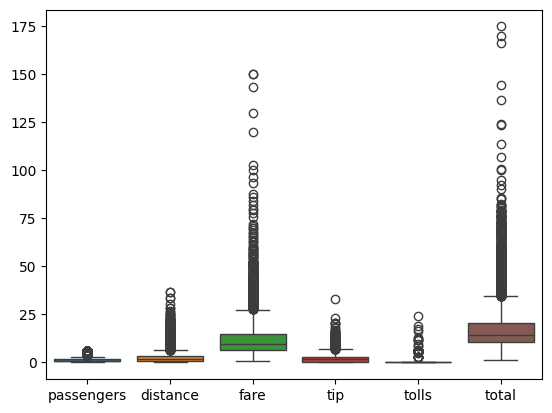

In [5]:
sns.boxplot(tx)

In [8]:
x = tx[['passengers', 'distance', 'fare']].copy()
x = (x - x.mean())/x.std()
y = tx['tip'].copy()
x, y

(      passengers  distance      fare
 0      -0.447969 -0.372170 -0.527283
 1      -0.447969 -0.583776 -0.700416
 2      -0.447969 -0.432256 -0.484000
 3      -0.447969  1.221407  1.204048
 4       1.213481 -0.225874 -0.354150
 ...          ...       ...       ...
 6428   -0.447969 -0.594226 -0.743700
 6429   -0.447969  4.105520  3.887612
 6430   -0.447969  0.291385  0.251816
 6431   -0.447969 -0.497566 -0.613850
 6432   -0.447969  0.215625  0.165249
 
 [6433 rows x 3 columns],
 0       2.15
 1       0.00
 2       2.36
 3       6.15
 4       1.10
         ... 
 6428    1.06
 6429    0.00
 6430    0.00
 6431    0.00
 6432    3.36
 Name: tip, Length: 6433, dtype: float64)

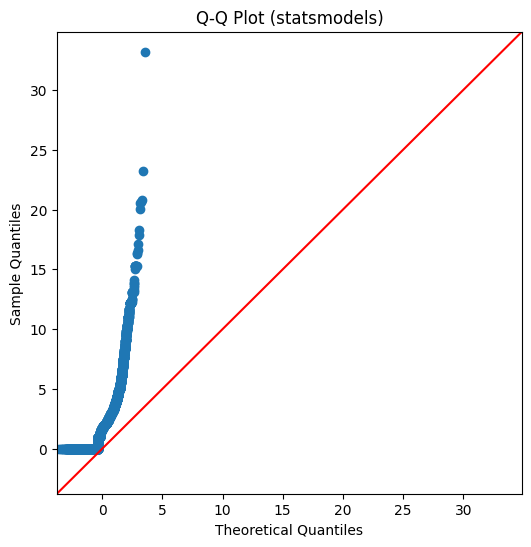

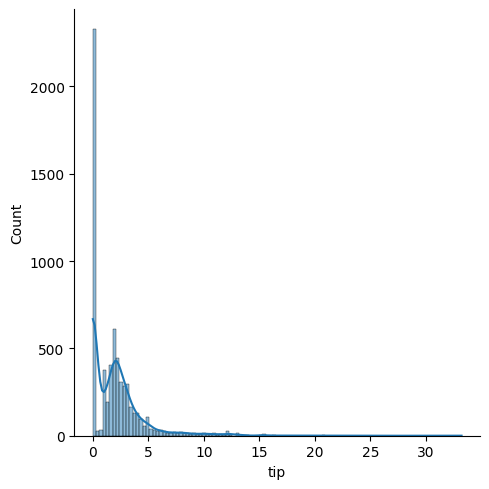

In [20]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(6, 6))
sm.graphics.qqplot(y, line='45', ax=plt.gca())   # 45° 라인(대각선) 추가
plt.title("Q‑Q Plot (statsmodels)")
plt.show()
sns.displot(y, kde=True)